## torch.randn函数

In [4]:
import torch

# 生成张量
x = torch.randn(10, 5)

# 设置打印选项
torch.set_printoptions(sci_mode=False, precision=4)

# 打印张量
print(x)


tensor([[ 0.2098, -0.4686,  0.8784,  0.1835,  0.1726],
        [-0.9036,  1.6398,  0.0155,  0.5887,  1.1371],
        [ 0.4337,  1.2026, -1.4230, -0.5013,  0.4730],
        [-0.0715,  0.6128,  0.0375, -0.3566, -0.5164],
        [ 1.3978,  1.3046, -0.6542, -0.4592,  0.7899],
        [ 0.2130, -0.6502, -0.3775, -0.1549, -0.2052],
        [-0.5148,  0.4970,  1.2584,  0.4423,  0.4555],
        [ 0.2623, -0.5498,  1.1698,  0.3251,  0.3476],
        [ 0.9549,  1.1554, -0.1622,  0.3623, -1.0117],
        [ 0.0261, -0.8791, -0.4891, -0.5116,  1.1483]])


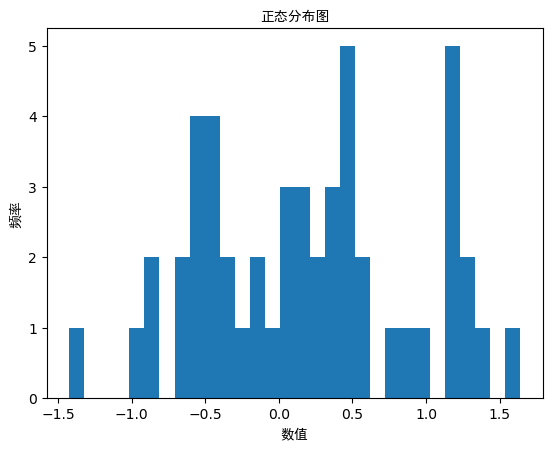

In [5]:
import torch
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties

# 设置中文字体
font = FontProperties(fname='C:\Windows\Fonts\simhei.ttf')  # 将'path_to_font_file.ttf'替换为字体文件的路径

# 绘制正态分布图
plt.hist(x.flatten().numpy(), bins=30)
plt.xlabel('数值', fontproperties=font)
plt.ylabel('频率', fontproperties=font)
plt.title('正态分布图', fontproperties=font)
plt.show()


In [6]:
# 计算张量的均值
mean = torch.mean(x)
print("均值:", mean)

# 计算张量的方差
variance = torch.var(x)
print("方差:", variance)

均值: tensor(0.1767)
方差: tensor(0.5240)


## 反向传播

In [8]:
import torch

x = torch.tensor([1.0, 2.0], requires_grad=True)
y = x * 2
z = y.mean()

y.retain_grad()  # 告诉PyTorch保留张量y的梯度

z.backward()  # 计算梯度

print(x.grad)  # x的梯度
print(y.grad)  # y的梯度


tensor([1., 1.])
tensor([0.5000, 0.5000])


## nn.Linear层

In [9]:
import torch
import torch.nn as nn

# 创建一个线性层，输入特征数为3，输出特征数为2
linear_layer = nn.Linear(3, 2)

# 输入样本
inputs = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])

# 将输入传递给线性层进行前向计算
outputs = linear_layer(inputs)

print(outputs)


tensor([[ 1.3127, -0.3262],
        [ 3.4788, -0.9179]], grad_fn=<AddmmBackward0>)


## 激活函数

In [10]:
import torch
import torch.nn as nn

x = torch.tensor([2.0, -1.0, 0.5])
sigmoid = nn.Sigmoid()

output = sigmoid(x)
print(output)

tensor([0.8808, 0.2689, 0.6225])


## 损失函数

In [17]:
import torch
import torch.nn as nn

criterion = nn.BCELoss()  # 创建BCELoss对象

output = torch.tensor([0.8, 0.2, 0.4])  # 模型的输出，表示样本属于正类的概率
target = torch.tensor([1, 0, 1], dtype=torch.float32)  # 真实标签，表示正类为1，负类为0

loss = criterion(output, target)  # 计算损失值
print(loss)

tensor(0.4542)


## 优化

## 单层感知机

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim

# 定义单层感知器模型
class Perceptron(nn.Module):
    def __init__(self, input_size):
        super(Perceptron, self).__init__()
        self.linear = nn.Linear(input_size, 1)
        self.sigmoid = nn.Sigmoid()
    
    def forward(self, x):
        out = self.linear(x)
        out = self.sigmoid(out)
        return out

# 定义训练数据
X = torch.tensor([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=torch.float32)
y = torch.tensor([[0], [0], [0], [1]], dtype=torch.float32)

# 初始化模型
input_size = X.shape[1]
model = Perceptron(input_size)
print(model)

# 定义优化器和损失函数
criterion = nn.BCELoss()
optimizer = optim.SGD(model.parameters(), lr=0.1)

# 训练模型
num_epochs = 1000
for epoch in range(num_epochs):
    # 前向传播
    outputs = model(X)
    loss = criterion(outputs, y)
    
    # 反向传播和优化
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    # 每100个epoch打印一次损失
    if (epoch+1) % 100 == 0:
        print('Epoch [{}/{}], Loss: {:.4f}'.format(epoch+1, num_epochs, loss.item()))

# 测试模型
with torch.no_grad():
    predicted = model(X)
    predicted = torch.round(predicted)  # 将输出舍入为0或1
    accuracy = (predicted == y).sum().item() / y.size(0)
    print('Accuracy: {:.2f}%'.format(accuracy * 100))


Perceptron(
  (linear): Linear(in_features=2, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
Epoch [100/1000], Loss: 0.5327
Epoch [200/1000], Loss: 0.4024
Epoch [300/1000], Loss: 0.3268
Epoch [400/1000], Loss: 0.2771
Epoch [500/1000], Loss: 0.2415
Epoch [600/1000], Loss: 0.2143
Epoch [700/1000], Loss: 0.1929
Epoch [800/1000], Loss: 0.1754
Epoch [900/1000], Loss: 0.1608
Epoch [1000/1000], Loss: 0.1484
Accuracy: 100.00%


## 简单神经网络

In [61]:
import torch

class PyTorchNeuralNetwork:
    def __init__(self, input_size, hidden_size, output_size):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        
        # 初始化权重和偏置
        self.W1 = torch.randn(self.input_size, self.hidden_size, requires_grad=True)
        self.b1 = torch.zeros(1, self.hidden_size, requires_grad=True)
        self.W2 = torch.randn(self.hidden_size, self.output_size, requires_grad=True)
        self.b2 = torch.zeros(1, self.output_size, requires_grad=True)
        
    def forward(self, X):
        # 前向传播
        self.z1 = torch.mm(X, self.W1) + self.b1
        self.a1 = torch.tanh(self.z1)
        self.z2 = torch.mm(self.a1, self.W2) + self.b2
        self.a2 = torch.sigmoid(self.z2)
        
        return self.a2
        
    def backward(self, X, y, learning_rate):
        m = X.shape[0]
        
        # 计算输出层的误差
        dZ2 = self.a2 - y
        dW2 = (1/m) * torch.mm(self.a1.T, dZ2)
        db2 = (1/m) * torch.sum(dZ2, dim=0, keepdim=True)
        
        # 计算隐藏层的误差
        dZ1 = torch.mm(dZ2, self.W2.T) * (1 - self.a1**2)
        dW1 = (1/m) * torch.mm(X.T, dZ1)
        db1 = (1/m) * torch.sum(dZ1, dim=0)
        
        # 更新权重和偏置
        self.W2.data -= learning_rate * dW2
        self.b2.data -= learning_rate * db2
        self.W1.data -= learning_rate * dW1
        self.b1.data -= learning_rate * db1
        
    def train(self, X, y, epochs, learning_rate):
        for epoch in range(epochs):
            # 前向传播
            output = self.forward(X)
            
            # 反向传播
            self.backward(X, y, learning_rate)
            
            # 计算损失
            loss = torch.mean((y - output) ** 2)
            
            # 每1000个epoch打印一次损失
            if epoch % 1000 == 0:
                print(f"Epoch {epoch}: Loss = {loss.item()}")
        
    def sigmoid(self, x):
        return 1 / (1 + torch.exp(-x))

# 创建PyTorch神经网络对象
input_size = 10
hidden_size = 15
output_size = 5

pytorch_nn = PyTorchNeuralNetwork(input_size, hidden_size, output_size)

# 定义训练数据和目标
X = torch.randn(100, input_size)
y = torch.randint(0, 2, size=(100, output_size))

# 训练神经网络
epochs = 10000
learning_rate = 0.1

# 训练PyTorch神经网络
pytorch_nn.train(X, y, epochs, learning_rate)

# 使用训练好的模型进行预测
input_data_torch = torch.randn(1, input_size)
output_torch = pytorch_nn.forward(input_data_torch)
print("预测结果：", output_torch) #.detach().numpy())

Epoch 0: Loss = 0.3873695135116577
Epoch 1000: Loss = 0.10359781235456467
Epoch 2000: Loss = 0.07110282778739929
Epoch 3000: Loss = 0.057106029242277145
Epoch 4000: Loss = 0.04365575313568115
Epoch 5000: Loss = 0.036599621176719666
Epoch 6000: Loss = 0.03173088654875755
Epoch 7000: Loss = 0.027670174837112427
Epoch 8000: Loss = 0.02467251382768154
Epoch 9000: Loss = 0.022429829463362694
预测结果： tensor([[0.0018, 0.8695, 0.8229, 0.8444, 0.0037]], grad_fn=<SigmoidBackward0>)


## Pytoch.nn实现的简单神经网络

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

# 定义神经网络模型
class CloudServiceUsageModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super(CloudServiceUsageModel, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

# 准备数据
input_size = 10
hidden_size = 5
num_classes = 2
learning_rate = 0.001
num_epochs = 100

# 随机生成一些示例数据
X = torch.randn(100, input_size)
Y = torch.randint(0, num_classes, (100,))

# 划分训练集和测试集
train_size = int(0.8 * len(X))
train_X, test_X = X[:train_size], X[train_size:]
train_Y, test_Y = Y[:train_size], Y[train_size:]

# 初始化模型、损失函数和优化器
model = CloudServiceUsageModel(input_size, hidden_size, num_classes)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# 模型训练
for epoch in range(num_epochs):
    # 前向传播
    outputs = model(train_X)
    loss = criterion(outputs, train_Y)

    # 反向传播和优化
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # 打印训练信息
    if (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {loss.item()}')

# 模型评估
with torch.no_grad():
    outputs = model(test_X)
    _, predicted = torch.max(outputs.data, 1)
    accuracy = (predicted == test_Y).sum().item() / len(test_Y)
    print(f'Test Accuracy: {accuracy}')


Epoch 10/100, Loss: 0.7254490852355957
Epoch 20/100, Loss: 0.7173128724098206
Epoch 30/100, Loss: 0.7097707986831665
Epoch 40/100, Loss: 0.7027563452720642
Epoch 50/100, Loss: 0.6960537433624268
Epoch 60/100, Loss: 0.6897956728935242
Epoch 70/100, Loss: 0.6836565732955933
Epoch 80/100, Loss: 0.6769127249717712
Epoch 90/100, Loss: 0.6696738004684448
Epoch 100/100, Loss: 0.6618732213973999
Test Accuracy: 0.3


In [ ]:
##

In [2]:
import logging

model_path = "c:/llama2/llama-2-7b-hf"

logging.basicConfig(level=logging.INFO)

logger = logging.getLogger()
logger.info(f"Reloaded SentencePiece model from {model_path}")

INFO:root:Reloaded SentencePiece model from c:/llama2/llama-2-7b-hf
